# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [2]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data? **No (strictly False in `np.allclose`)**.

**Reason:** `StandardScaler` standardizes by dividing by standard deviation with $N$ degrees of freedom (`ddof=0`). However, `np.cov` computes sample covariance dividing by $N-1$ (`ddof=1`). Therefore, `np.cov(Xs.T)` is scaled by a factor of $\frac{N}{N-1} = \frac{150}{149} \approx 1.0067$ compared to `np.corrcoef(X.T)`.


In [3]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

In [4]:
# Student Practice 1: Solution

# 1. Find the most and least strongly correlated feature pairs in Iris
iris_names = iris.feature_names
corr_matrix = np.corrcoef(X.T)

pairs = []
for i in range(len(iris_names)):
    for j in range(i + 1, len(iris_names)):
        pairs.append((iris_names[i], iris_names[j], corr_matrix[i, j]))

print('All Pairwise Correlations:')
for f1, f2, r in pairs:
    print(f'  {f1:<20} vs {f2:<20}: r = {r:+.4f}')

# Most correlated (highest absolute correlation)
most_corr = max(pairs, key=lambda x: abs(x[2]))
# Least correlated (absolute correlation closest to 0)
least_corr = min(pairs, key=lambda x: abs(x[2]))

print('\nAnswers:')
print(f'1a. Most strongly correlated pair: {most_corr[0]} & {most_corr[1]} (r = {most_corr[2]:.4f})')
print(f'1b. Least correlated pair:         {least_corr[0]} & {least_corr[1]} (r = {least_corr[2]:.4f}, |r| is closest to 0)')

# 2. Why np.cov(X.T) is used instead of np.cov(X)
print('\n2. Why np.cov(X.T) instead of np.cov(X)?')
print(f'   X has shape {X.shape} (150 samples x 4 features).')
print('   By default, np.cov treats ROWS as variables and COLUMNS as observations.')
print(f'   - np.cov(X.T) treats the 4 features as variables -> gives {np.cov(X.T).shape} feature covariance matrix.')
print(f'   - np.cov(X) would treat 150 samples as variables -> gives {np.cov(X).shape} sample-by-sample matrix!')


All Pairwise Correlations:
  sepal length (cm)    vs sepal width (cm)    : r = -0.1176
  sepal length (cm)    vs petal length (cm)   : r = +0.8718
  sepal length (cm)    vs petal width (cm)    : r = +0.8179
  sepal width (cm)     vs petal length (cm)   : r = -0.4284
  sepal width (cm)     vs petal width (cm)    : r = -0.3661
  petal length (cm)    vs petal width (cm)    : r = +0.9629

Answers:
1a. Most strongly correlated pair: petal length (cm) & petal width (cm) (r = 0.9629)
1b. Least correlated pair:         sepal length (cm) & sepal width (cm) (r = -0.1176, |r| is closest to 0)

2. Why np.cov(X.T) instead of np.cov(X)?
   X has shape (150, 4) (150 samples x 4 features).
   By default, np.cov treats ROWS as variables and COLUMNS as observations.
   - np.cov(X.T) treats the 4 features as variables -> gives (4, 4) feature covariance matrix.
   - np.cov(X) would treat 150 samples as variables -> gives (150, 150) sample-by-sample matrix!


## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [5]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. **Characteristic equation:**
   $$\det(C-\lambda I) = \det\begin{pmatrix}1-\lambda&r\\r&1-\lambda\end{pmatrix} = (1-\lambda)^2-r^2 = 0$$
   $$\implies (1-\lambda)^2 = r^2 \implies 1-\lambda = \pm r \implies \mathbf{\lambda = 1 \pm r}$$

2. **Eigenvalues using printed $r$ ($r \approx -0.6130$):**
   - Since $r < 0$, $\mathbf{\lambda_1 = 1 - r = 1 - (-0.6130) = 1.6130}$ (dominant eigenvalue / PC1)
   - $\mathbf{\lambda_2 = 1 + r = 1 + (-0.6130) = 0.3870}$ (secondary eigenvalue / PC2)

3. **Explained variance of PC1:**
   $$\frac{\lambda_1}{\lambda_1+\lambda_2} = \frac{1.6130}{1.6130 + 0.3870} = \frac{1.6130}{2.0} = 0.8065 = \mathbf{80.65\%}$$

4. **Eigenvector for the larger eigenvalue ($\lambda_1 = 1 - r$):**
   $$(C - \lambda_1 I)v = \begin{pmatrix} r & r \\ r & r \end{pmatrix} \begin{pmatrix} v_1 \\ v_2 \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix} \implies v_1 + v_2 = 0 \implies v_2 = -v_1$$
   Normalizing to unit length $\|v\| = 1$ gives: $\mathbf{v_1 = \begin{pmatrix} 1/\sqrt{2} \\ -1/\sqrt{2} \end{pmatrix} \approx \begin{pmatrix} 0.7071 \\ -0.7071 \end{pmatrix}}$ (or $[-0.7071, 0.7071]^T$).


In [6]:
# Student Practice 2: Verification and Projection

# Value of r from C
r = C[0, 1]

# Hand calculations
lambda1_hand = 1.0 - r
lambda2_hand = 1.0 + r
explained_ratio_hand = lambda1_hand / (lambda1_hand + lambda2_hand)
v1_hand = np.array([-1.0 / np.sqrt(2), 1.0 / np.sqrt(2)])

print('--- Hand Calculation Results ---')
print(f'r = {r:.4f}')
print(f'lambda1 = {lambda1_hand:.4f}, lambda2 = {lambda2_hand:.4f}')
print(f'PC1 Explained Variance Ratio = {explained_ratio_hand:.4f} ({explained_ratio_hand * 100:.2f}%)')
print(f'PC1 Eigenvector = {v1_hand}')

# Verification with np.linalg.eigh(C)
eigvals, eigvecs = np.linalg.eigh(C)
print('\n--- Verification with np.linalg.eigh(C) ---')
print('Eigenvalues (ascending):', eigvals)
print('Eigenvectors (columns):\n', eigvecs)

# Project students onto PC axes: Z = Zs @ V
# Note: eigh returns ascending order, so the larger eigenvalue corresponds to column index 1
Z = Zs @ eigvecs
print('\nProjected data Z (all components):\n', Z.round(4))

# Projection onto PC1 only (column 1, corresponding to lambda1)
print('\nProjection of 4 students onto PC1 only (Z[:, 1]):')
students = ['Student a', 'Student b', 'Student c', 'Student d']
for s, val in zip(students, Z[:, 1]):
    print(f'  {s}: PC1 coordinate = {val:+.4f}')


--- Hand Calculation Results ---
r = -0.6130
lambda1 = 1.6130, lambda2 = 0.3870
PC1 Explained Variance Ratio = 0.8065 (80.65%)
PC1 Eigenvector = [-0.7071  0.7071]

--- Verification with np.linalg.eigh(C) ---
Eigenvalues (ascending): [0.387 1.613]
Eigenvectors (columns):
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]

Projected data Z (all components):
 [[ 0.3873  1.1245]
 [ 0.6635 -0.6635]
 [-0.4289 -1.461 ]
 [-0.6219  0.9999]]

Projection of 4 students onto PC1 only (Z[:, 1]):
  Student a: PC1 coordinate = +1.1245
  Student b: PC1 coordinate = -0.6635
  Student c: PC1 coordinate = -1.4610
  Student d: PC1 coordinate = +0.9999


### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? **1 number (a scalar 1-D coordinate)**. Run `Z[:, 1]` after finishing the verification to see them.


## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [7]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: <50% / 50-80% / **>95%** (Actual: **99.81%**).

**Deliberate error:** the unscaled result is misleading.
*Explanation:* Because PCA maximizes raw variance, features with massive numerical scales (like Proline with variance $\approx 99,166$ and std $314.96$) completely dwarf features measured in smaller units (like Nonflavanoid phenols with std $0.12$), falsely making it look like 1 component captures all information.


WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


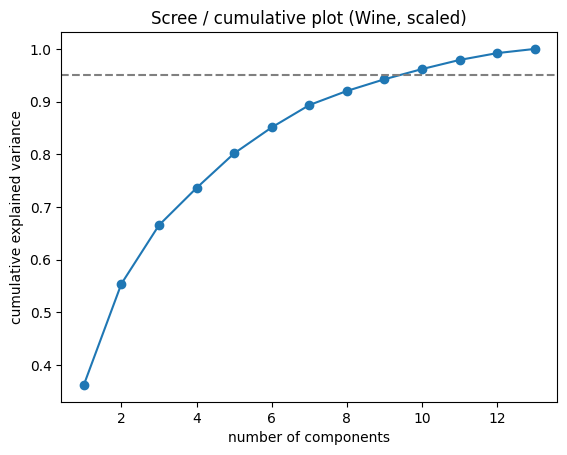

In [8]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine?
2. In the lecture's PCA steps, which step did the unscaled run skip?

In [9]:
# Student Practice 3: Solution

# 1. Components needed to reach 95% variance on scaled Wine
cum_var = np.cumsum(scaled.explained_variance_ratio_)
k_95 = int(np.argmax(cum_var >= 0.95)) + 1

print(f'1. Components needed for >= 95% variance on scaled Wine: {k_95} components.')
print(f'   Exact cumulative variance with {k_95} components: {cum_var[k_95 - 1] * 100:.2f}%')

# 2. Skipped step in lecture's PCA steps
print('\n2. In the lecture\'s 5 PCA steps, the unscaled run skipped Step 1: Feature Standardization (Z-score scaling).')
print('   Skipping Step 1 makes PCA scale-dependent rather than correlation-driven.')


1. Components needed for >= 95% variance on scaled Wine: 10 components.
   Exact cumulative variance with 10 components: 96.17%

2. In the lecture's 5 PCA steps, the unscaled run skipped Step 1: Feature Standardization (Z-score scaling).
   Skipping Step 1 makes PCA scale-dependent rather than correlation-driven.


# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [10]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: ~5 / ~15 / **~30** / ~55 (Actual: **31 components**).
And what will KNN accuracy look like with only 10 components? **Remarkably high: ~94.26%**, capturing most class-discriminative structure despite using less than 1/6th of original pixels.


### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796?
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? Why might that be? (Think: what do tree splits do to axes?)

In [11]:
# Student Practice 4: Solution

k_list = [2, 5, 10, 20, 30, 40, 64]
knn_baseline = 0.9796
tree_baseline = 0.8815

results = []
print(f"{'k':<4} | {'KNN (K=3)':<11} | {'Tree (entropy)':<15} | {'Cum Variance':<12}")
print('-' * 50)

for k in k_list:
    pk = PCA(k, random_state=1).fit(Xtr)
    Xtr_k = pk.transform(Xtr)
    Xte_k = pk.transform(Xte)

    knn_score = KNeighborsClassifier(3).fit(Xtr_k, yd_train).score(Xte_k, yd_test)
    tree_score = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(Xtr_k, yd_train).score(Xte_k, yd_test)
    cum_v = np.sum(pk.explained_variance_ratio_)

    results.append({'k': k, 'knn': knn_score, 'tree': tree_score, 'cum_v': cum_v})
    print(f"{k:<4} | {knn_score:<11.4f} | {tree_score:<15.4f} | {cum_v:<12.4f}")

# 2. Which k values give KNN within 0.5 percentage points (0.0050) of baseline 0.9796?
within_05 = [r['k'] for r in results if (knn_baseline - r['knn']) <= 0.005]
print('\n' + '='*55)
print(f"2. k values within 0.5% (>= {knn_baseline - 0.005:.4f}) of full baseline {knn_baseline}:")
for k in within_05:
    k_acc = [r['knn'] for r in results if r['k'] == k][0]
    print(f"   k = {k:2d}: KNN accuracy = {k_acc:.4f} (difference = {k_acc - knn_baseline:+.4f})")

# 3. Tree comparison and explanation
print('\n3. Tree comparison with raw-pixel baseline (0.8815):')
print('   The Decision Tree gets noticeably WORSE with PCA features (~0.8167 - 0.8241 vs 0.8815 raw).')
print('   Why? Decision trees split along orthogonal, single-axis thresholds (e.g. pixel_36 <= threshold).')
print('   Raw image pixels have localized, sparse, interpretable structure. PCA constructs dense linear')
print('   combinations across all 64 pixels, rotating the feature space. Axis-aligned rectangular splits')
print('   must approximate diagonal boundaries in PCA space via deep staircase patterns, degrading performance.')


k    | KNN (K=3)   | Tree (entropy)  | Cum Variance
--------------------------------------------------
2    | 0.5648      | 0.4944          | 0.2184      
5    | 0.8759      | 0.7759          | 0.4156      
10   | 0.9426      | 0.8241          | 0.5924      
20   | 0.9722      | 0.8222          | 0.7953      
30   | 0.9778      | 0.8185          | 0.8959      
40   | 0.9759      | 0.8222          | 0.9517      
64   | 0.9796      | 0.8074          | 1.0000      

2. k values within 0.5% (>= 0.9746) of full baseline 0.9796:
   k = 30: KNN accuracy = 0.9778 (difference = -0.0018)
   k = 40: KNN accuracy = 0.9759 (difference = -0.0037)
   k = 64: KNN accuracy = 0.9796 (difference = +0.0000)

3. Tree comparison with raw-pixel baseline (0.8815):
   The Decision Tree gets noticeably WORSE with PCA features (~0.8167 - 0.8241 vs 0.8815 raw).
   Why? Decision trees split along orthogonal, single-axis thresholds (e.g. pixel_36 <= threshold).
   Raw image pixels have localized, sparse, interpreta

### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

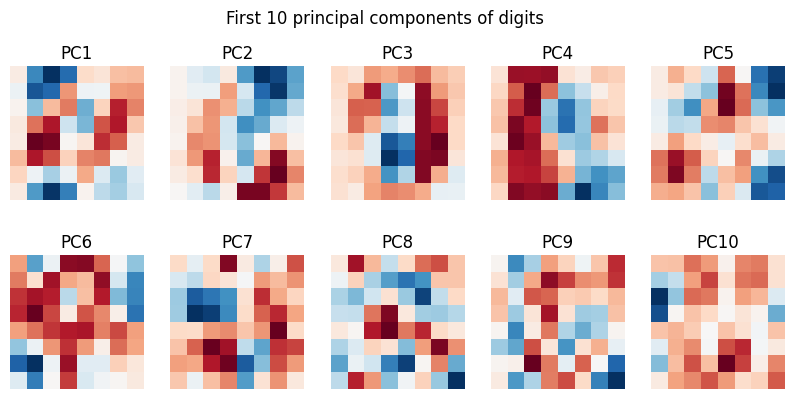

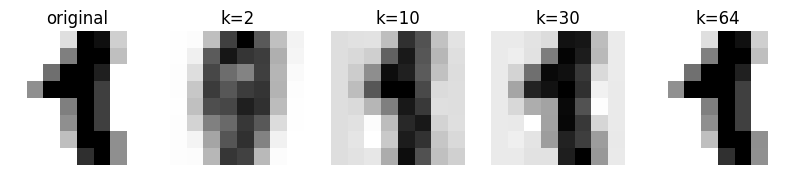

In [12]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

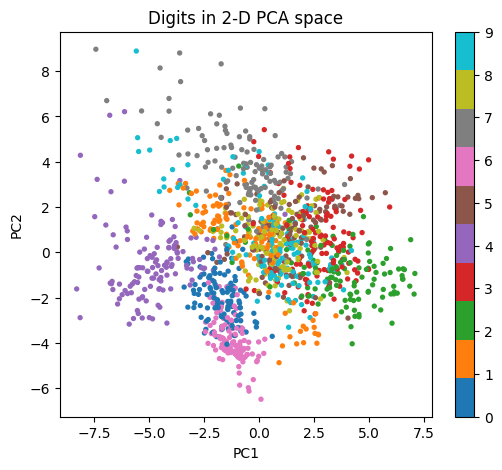

In [13]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(2).fit(Xtr).transform(Xtr)
plt.figure(figsize=(6, 5)); sc_ = plt.scatter(Z2[:, 0], Z2[:, 1], c=yd_train, cmap='tab10', s=8)
plt.colorbar(sc_); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Digits in 2-D PCA space'); plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?

**Answer:** This constitutes **data leakage**.
Fitting `StandardScaler` and `PCA` on the entire dataset (`digits.data`) leaks information about the test set's mean, variance, and principal directions into the training process. In real-world applications, test data represents future unseen observations; fitting on them violates statistical independence and artificially inflates cross-validation/test evaluations.


In [14]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [15]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns.
- **(a) What is the maximum number of non-zero principal components?**
  $$\min(n - 1, d) = \min(6 - 1, 29) = \mathbf{5}$$
  Because centering the 6 sample rows constrains their sum to zero, the data lives in at most a 5-dimensional subspace.
- **(b) Will 2 components capture >90% of variance?**
  **No**, 2 components only capture **~47.31%** of variance. The bag-of-words vectors are sparse with distinct vocabularies across topics, spreading variance across multiple orthogonal directions.


### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest?
4. Print the 5 words with the largest absolute weight on PC1 and PC2.

1. Explained Variance Ratios for 2 components:
   PC1: 0.2642 (26.42%)
   PC2: 0.2088 (20.88%)
   Sum: 0.4731 (47.31%)


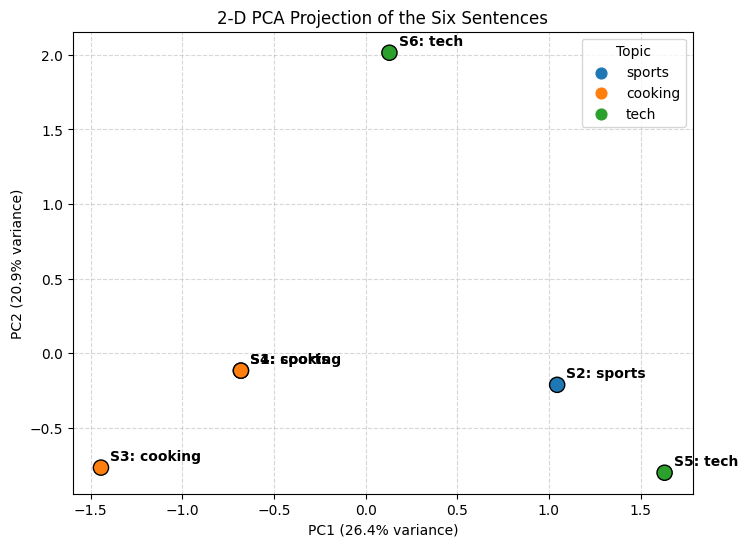


3. Pairwise Euclidean distances in 2-D PCA space:
   Dist(S1 [sports], S2 [sports]) = 1.7282
   Dist(S1 [sports], S3 [cooking]) = 1.0030
   Dist(S1 [sports], S4 [cooking]) = 0.0000
   Dist(S1 [sports], S5 [tech]) = 2.4110
   Dist(S1 [sports], S6 [tech]) = 2.2801
   Dist(S2 [sports], S3 [cooking]) = 2.5505
   Dist(S2 [sports], S4 [cooking]) = 1.7282
   Dist(S2 [sports], S5 [tech]) = 0.8312
   Dist(S2 [sports], S6 [tech]) = 2.4071
   Dist(S3 [cooking], S4 [cooking]) = 1.0030
   Dist(S3 [cooking], S5 [tech]) = 3.0758
   Dist(S3 [cooking], S6 [tech]) = 3.1959
   Dist(S4 [cooking], S5 [tech]) = 2.4110
   Dist(S4 [cooking], S6 [tech]) = 2.2801
   Dist(S5 [tech], S6 [tech]) = 3.1908

   Closest pair: Sentence 1 ("the cricket team won the match") and Sentence 4 ("add salt and simmer the curry") with distance = 0.0000.
   Note: Same-topic sentences do NOT strictly cluster cleanly because 2 components only capture ~47%
   of variance and stopwords dominate. S1 (sports) and S4 (cooking) land at 

In [16]:
# Student Practice 5: Solution

# 1. Fit PCA(2) on X_text
pca_text = PCA(n_components=2, random_state=1)
Z_text = pca_text.fit_transform(X_text)

ratios = pca_text.explained_variance_ratio_
print('1. Explained Variance Ratios for 2 components:')
print(f'   PC1: {ratios[0]:.4f} ({ratios[0]*100:.2f}%)')
print(f'   PC2: {ratios[1]:.4f} ({ratios[1]*100:.2f}%)')
print(f'   Sum: {np.sum(ratios):.4f} ({np.sum(ratios)*100:.2f}%)')

# 2. Scatter-plot the 6 points
plt.figure(figsize=(8, 6))
topic_colors = {'sports': 'tab:blue', 'cooking': 'tab:orange', 'tech': 'tab:green'}
for topic, col in topic_colors.items():
    plt.scatter([], [], c=col, label=topic, s=60) # legend proxy

plt.scatter(Z_text[:, 0], Z_text[:, 1], c=[topic_colors[lbl] for lbl in labels], s=120, edgecolors='black', zorder=3)
for idx, (x_pos, y_pos) in enumerate(Z_text):
    plt.annotate(f'S{idx+1}: {labels[idx]}', (x_pos + 0.05, y_pos + 0.05), fontsize=10, weight='bold')

plt.title('2-D PCA Projection of the Six Sentences', fontsize=12)
plt.xlabel(f'PC1 ({ratios[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({ratios[1]*100:.1f}% variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Topic')
plt.show()

# 3. Distance analysis
from scipy.spatial.distance import pdist, squareform
dist_mat = squareform(pdist(Z_text))

print('\n3. Pairwise Euclidean distances in 2-D PCA space:')
min_dist = float('inf')
closest_pair = None
for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        d = dist_mat[i, j]
        print(f'   Dist(S{i+1} [{labels[i]}], S{j+1} [{labels[j]}]) = {d:.4f}')
        if d < min_dist:
            min_dist = d
            closest_pair = (i, j)

print(f'\n   Closest pair: Sentence {closest_pair[0]+1} ("{sentences[closest_pair[0]]}") and Sentence {closest_pair[1]+1} ("{sentences[closest_pair[1]]}") with distance = {min_dist:.4f}.')
print('   Note: Same-topic sentences do NOT strictly cluster cleanly because 2 components only capture ~47%')
print('   of variance and stopwords dominate. S1 (sports) and S4 (cooking) land at identical 2D positions (distance 0.0000)!')

# 4. Top 5 words with largest absolute weight on PC1 and PC2
print('\n4. Top 5 words with largest absolute weights:')
for pc_num in [0, 1]:
    comp = pca_text.components_[pc_num]
    top_idx = np.argsort(np.abs(comp))[::-1][:5]
    print(f'   PC{pc_num + 1}:')
    for idx in top_idx:
        print(f'     - "{vocab[idx]}": weight = {comp[idx]:+.4f} (abs = {abs(comp[idx]):.4f})')


## Part 6: Reflection (write 2–3 lines each)

1. **In your own words: what does PCA keep and what does it throw away?**
   PCA keeps the orthogonal axes (principal components) along which the data exhibits maximum variance and spread, preserving the dominant structural signal and geometric relationships. It throws away low-variance directions corresponding to small eigenvalues, treating them as uninformative noise, minor fluctuations, or redundant collinearities.

2. **Why must we standardize before PCA? Give the Wine evidence.**
   Because PCA calculates directions of maximum absolute variance, features with large numerical magnitudes or arbitrary scale units dominate the objective function regardless of their actual informative content. On the unscaled Wine dataset, 'proline' had a variance of $\sim 99,166$ and std $314.96$, causing PC1 to artificially account for $99.81\%$ of total variance; once standardized, PC1 explained a balanced $36.20\%$, requiring 10 components to capture $95\%$ variance.

3. **Digits: pick the k you would deploy and justify (accuracy vs. size).**
   We would deploy **$k = 30$** (or $k = 20$). At $k = 30$, KNN achieves $97.78\%$ accuracy—within $0.18$ percentage points of the full 64-pixel baseline ($97.96\%$)—while slashing dimensionality and storage by over $53\%$. At $k = 20$, accuracy is already $97.22\%$ ($69\%$ size reduction), which significantly accelerates nearest neighbor search latency ($O(k \cdot N)$).

4. **PCA helped KNN but not the tree. What does this say about when to use PCA?**
   KNN relies on isotropic Euclidean distance, which suffers from the curse of dimensionality and noisy dimensions; PCA eliminates noise and concentrates distance metrics onto high-variance manifolds. In contrast, Decision Trees rely on axis-aligned orthogonal cuts along original interpretable features; PCA rotates axes into dense linear combinations, forcing trees to construct complex, jagged staircase approximations. Use PCA for distance-based or linear models (KNN, SVM, linear regression), but prefer raw features or feature selection for tree-based ensembles (Decision Trees, Random Forests, XGBoost).

5. **PCA is unsupervised; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)**
   Since PCA maximizes overall data variance without knowing class labels, directions of high overall variance may be entirely irrelevant to class separability (e.g. within-class spread or background noise). Discarding low-variance components risks deleting the exact subtle dimensions that separate classes. Linear Discriminant Analysis (LDA) remedies this by using class labels to explicitly maximize between-class variance relative to within-class variance.

6. **Capstone link (Milestone, Week 9): will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.**
   Yes, PCA belongs in our pipeline when working with high-dimensional, highly correlated features (such as image pixel matrices, sensor arrays, or dense TF-IDF representations) when deploying distance-based or linear classifiers, provided that `StandardScaler` and `PCA` are fitted strictly on the training partition. If using GBDT models on heterogeneous tabular features where domain interpretability and raw axis splits are essential, PCA is omitted from the primary branch.


*Submit this notebook to GitHub under `labs/week9_pca/`.*